In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
# Carga inicial
df = pd.read_csv('/content/ordenes_limpias.csv')

# Vista previa de las primeras y últimas filas
print(f"Dimensiones del dataset: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Dimensiones del dataset: 5608 filas, 30 columnas


,waybill,company,customer_id,order_date,order_year,order_month,origin,destination_port,delivery_dest,currency,container_type,total_skids,lead_time_days,ocean_carrier,land_carrier,base_ocean_rate,invoice_rate_markup,ocean_cost,land_cost,ocean_surcharge,final_surcharge,land_freight_invoiced,surcharge_discount,land_freight_discount,ocean_value_change,original_destination,original_ocean_value,delivery_state,ocean_cost_per_skid,land_cost_per_skid
0,27410,1,463,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","Santa Fe Springs, CA",USD,40FT,11.04295,34.0,Northstar Express,MAV Transportation,2841.5,1.3,2713.92,784.36,312.56,0.0,1019.67,0.0,0.0,CutOff,NaN,NaN,CA,245.760417,71.028122
1,27412,1,245,2024-01-02,2024,1,Shanghai,"Portland, OR","Jefferson OR United States, of",USD,LCL,1.25000,55.0,Northstar Express,Northstar Express,2000.0,1.3,1089.00,445.00,-152.00,0.0,578.50,0.0,0.0,NaN,NaN,NaN,of,871.200000,356.000000
2,27413,1,20,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","NIPOMO, CA",USD,40FT,21.00000,69.0,Northstar Express,Northstar Express,3000.0,1.2,3716.14,1450.00,1475.14,0.0,1740.00,0.0,0.0,NaN,NaN,NaN,CA,176.959048,69.047619
3,27414,1,20,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","NIPOMO, CA",USD,40FT,22.00000,48.0,Northstar Express,Northstar Express,3400.0,1.2,3816.14,1450.00,1175.14,0.0,1740.00,0.0,0.0,NaN,NaN,NaN,CA,173.460909,65.909091
4,27415,1,843,2024-01-02,2024,1,Shanghai,"Chicago, IL","Oxford , PA",USD,40FT,0.44155,55.0,Northstar Express,Navegate Land,86.4,1.3,144.04,345.88,74.03,0.0,449.64,0.0,0.0,NaN,NaN,NaN,PA,326.214472,783.331446


In [3]:
# Resumen de columnas, tipos y valores no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5608 entries, 0 to 5607
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   waybill                5608 non-null   int64  
 1   company                5608 non-null   int64  
 2   customer_id            5608 non-null   int64  
 3   order_date             5608 non-null   object 
 4   order_year             5608 non-null   int64  
 5   order_month            5608 non-null   int64  
 6   origin                 5608 non-null   object 
 7   destination_port       5608 non-null   object 
 8   delivery_dest          5472 non-null   object 
 9   currency               5608 non-null   object 
 10  container_type         5608 non-null   object 
 11  total_skids            5608 non-null   float64
 12  lead_time_days         5597 non-null   float64
 13  ocean_carrier          5511 non-null   object 
 14  land_carrier           5504 non-null   object 
 15  base

In [4]:
# Variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
waybill,5608.0,31973.421897,2619.182519,27410.0000,29546.750000,32077.500000,34275.500000,36903.000000
company,5608.0,1.313659,0.464021,1.0000,1.000000,1.000000,2.000000,2.000000
customer_id,5608.0,292.112696,317.409305,6.0000,72.000000,158.000000,459.000000,1313.000000
order_year,5608.0,2024.729315,0.681627,2024.0000,2024.000000,2025.000000,2025.000000,2026.000000
order_month,5608.0,6.559023,3.171133,1.0000,4.000000,7.000000,9.000000,12.000000
total_skids,5608.0,24.161597,75.997003,0.0476,5.000000,20.000000,20.000000,895.000000
lead_time_days,5597.0,107.884581,36.457637,3.0000,84.000000,104.000000,125.000000,384.000000
base_ocean_rate,5608.0,4194.433324,2747.932801,0.0000,1441.702500,4600.000000,6251.137500,20000.000000
invoice_rate_markup,5608.0,1.254699,0.052956,1.1000,1.200000,1.300000,1.300000,1.300000
ocean_cost,5608.0,3866.711794,3010.135301,6.0100,1121.517500,3367.570000,5863.297500,15778.420000


In [5]:
# Variables categóricas/objeto
df.describe(include=['O', 'category']).T

,count,unique,top,freq
order_date,5608,624,2025-09-09,57
origin,5608,2,Shanghai,4746
destination_port,5608,45,"Toronto, ON",868
delivery_dest,5472,422,"Chilliwack, BC",308
currency,5608,2,USD,3889
container_type,5608,3,40FT,5542
ocean_carrier,5511,5,Northstar Express,3568
land_carrier,5504,15,Northstar Express,1431
ocean_value_change,255,3,CutOff,244
original_destination,92,16,"Savannah, GA",27


In [6]:
# Identificar identificadores únicos, constantes o categóricas de alta cardinalidad
df.nunique().to_frame(name='Valores Únicos').sort_values(by='Valores Únicos', ascending=False)

,Valores Únicos
waybill,5608
ocean_surcharge,4819
ocean_cost,4170
ocean_cost_per_skid,4108
land_cost_per_skid,3094
land_cost,2648
land_freight_invoiced,2643
base_ocean_rate,2168
final_surcharge,817
order_date,624


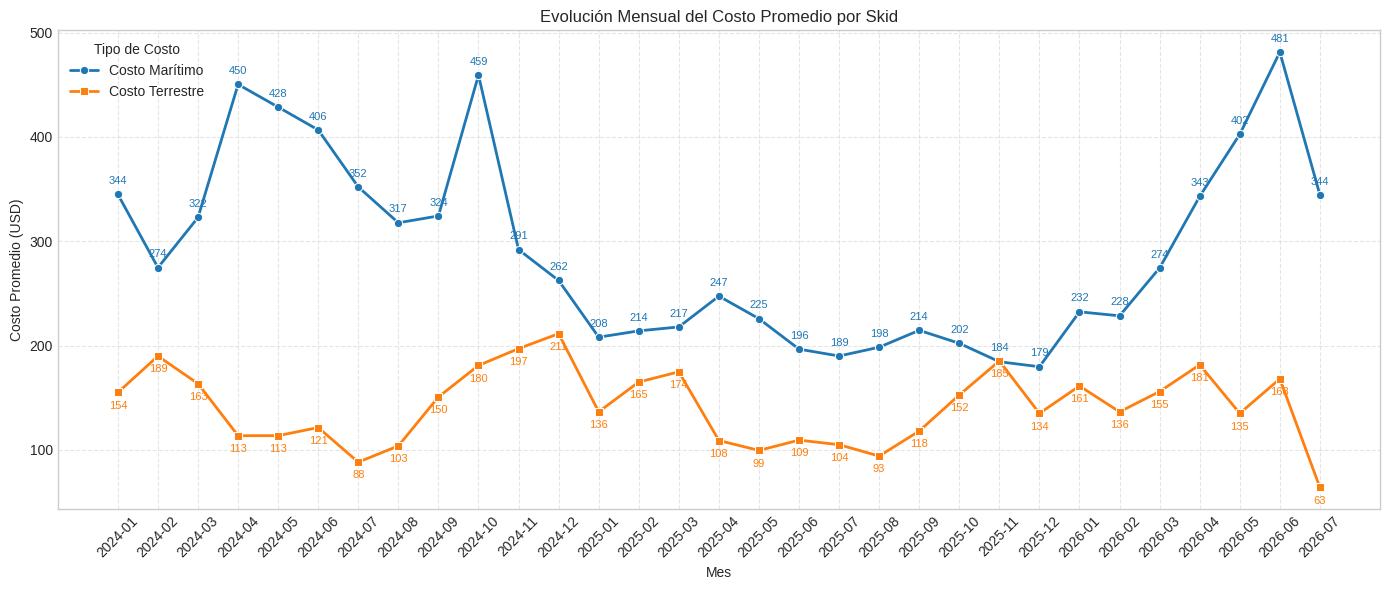

In [20]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['year_month'] = df['order_date'].dt.to_period('M')

# Calcular costo promedio por skid mensual
monthly_costs = df.groupby('year_month')[['ocean_cost_per_skid', 'land_cost_per_skid']].mean().reset_index()
monthly_costs['year_month'] = monthly_costs['year_month'].astype(str)
plt.figure(figsize=(14, 6))

sns.lineplot(data=monthly_costs, x='year_month', y='ocean_cost_per_skid',
             label='Costo Marítimo', marker='o', linewidth=2, color='#1f77b4')

sns.lineplot(data=monthly_costs, x='year_month', y='land_cost_per_skid',
             label='Costo Terrestre', marker='s', linewidth=2, color='#ff7f0e')

# Iterar sobre los datos para agregar el texto en cada punto
for index, row in monthly_costs.iterrows():
    # Etiqueta para el costo marítimo (desplazada hacia arriba)
    plt.text(index, row['ocean_cost_per_skid'] + 8, f"{int(row['ocean_cost_per_skid'])}",
             ha='center', va='bottom', fontsize=8, color='#1f77b4')

    # Etiqueta para el costo terrestre (desplazada hacia abajo)
    plt.text(index, row['land_cost_per_skid'] - 8, f"{int(row['land_cost_per_skid'])}",
             ha='center', va='top', fontsize=8, color='#ff7f0e')

plt.title('Evolución Mensual del Costo Promedio por Skid')
plt.xticks(rotation=45)
plt.ylabel('Costo Promedio (USD)')
plt.xlabel('Mes')

plt.legend(title='Tipo de Costo')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis de Evolución Temporal de Costos por Skid

El costo marítimo domina la estructura de gastos por skid y es el principal generador de volatilidad, mientras que el costo terrestre se mantiene en una banda mucho más estable y predecible.

**1. Volatilidad del Costo Marítimo**
* El transporte marítimo presenta fluctuaciones drásticas con tres picos principales a lo largo de la serie: abril de 2024 (450 USD), octubre de 2024 (459 USD) y un máximo histórico en junio de 2026 (481 USD).
* Existe un periodo prolongado de estabilización a la baja durante todo el año 2025, alcanzando su punto más económico en diciembre de 2025 con 179 USD, lo que estrechó la brecha con los costos terrestres.
* A partir de enero de 2026, la métrica muestra una tendencia fuertemente alcista que culmina en la escalada abrupta de mediados de ese año, antes de corregirse a 344 USD en julio.

**2. Estabilidad del Costo Terrestre**
* Los costos terrestres fluctúan en un rango estrecho, manteniéndose habitualmente entre los 88 USD (julio de 2024) y los 211 USD (diciembre de 2024).
* El mes más económico para la operación terrestre en todo el periodo analizado es el cierre de la gráfica en julio de 2026, cayendo a 63 USD.
* No existe una correlación temporal con los choques de precios oceánicos; por ejemplo, durante el máximo marítimo de junio de 2026 (481 USD), el costo terrestre se mantuvo en un nivel promedio de 168 USD.
** Conclusion **
La amplitud de la brecha entre ambos costos es el factor que dictamina las variaciones presupuestales del periodo. Las métricas evidencian que el riesgo financiero de la cadena de suministro recae casi por completo en el tramo marítimo, dado que las tarifas terrestres absorben los impactos macroeconómicos sin trasladar picos atípicos al costo final por unidad.

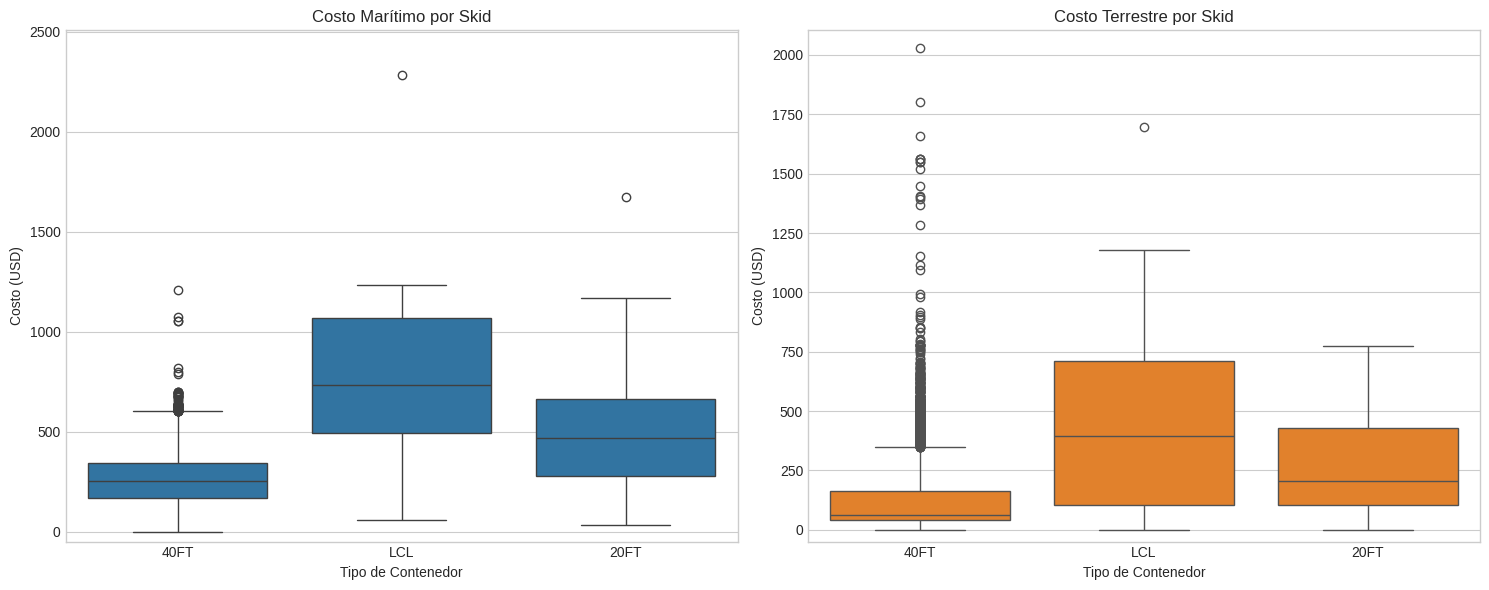

In [24]:
# Función para calcular dónde termina el bigote superior (Q3 + 1.5 * IQR)
def maximo_bigote(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q3 + 1.5 * iqr

# Encontramos el bigote más alto para mar y tierra
limite_mar = df.groupby('container_type')['ocean_cost_per_skid'].apply(maximo_bigote).max()
limite_tierra = df.groupby('container_type')['land_cost_per_skid'].apply(maximo_bigote).max()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfica Marítima
sns.boxplot(data=df, x='container_type', y='ocean_cost_per_skid', ax=axes[0], color='#1f77b4')
axes[0].set_title('Costo Marítimo por Skid')
axes[0].set_ylabel('Costo (USD)')
axes[0].set_xlabel('Tipo de Contenedor')
# Ajustamos el límite Y al máximo bigote + 30% de espacio
axes[0].set_ylim(-50, limite_mar * 1.3)

# Gráfica Terrestre
sns.boxplot(data=df, x='container_type', y='land_cost_per_skid', ax=axes[1], color='#ff7f0e')
axes[1].set_title('Costo Terrestre por Skid')
axes[1].set_ylabel('Costo (USD)')
axes[1].set_xlabel('Tipo de Contenedor')
# Ajustamos el límite Y al máximo bigote + 30% de espacio
axes[1].set_ylim(-50, limite_tierra * 1.3)

plt.tight_layout()
plt.show()

### Análisis de Distribución de Costos por Tipo de Contenedor

El análisis de la distribución de costos revela diferencias estructurales significativas dependiendo del tipo de contenedor utilizado, manteniendo un comportamiento consistente tanto en el trayecto marítimo como en el terrestre.

**1. Eficiencia del Contenedor de 40FT**
* El contenedor de 40 pies (40FT) se consolida como la opción más eficiente y económica por skid, presentando la mediana de costo más baja en ambos trayectos.
* Su rango intercuartílico (la caja donde se concentra el 50% de los datos) es notablemente compacto, lo que indica que sus tarifas base son muy estables y predecibles.
* Sin embargo, en el costo terrestre, el 40FT presenta una densa concentración de valores atípicos (outliers) que superan los 1,500 USD, lo que sugiere que ciertas rutas específicas o complicaciones de última milla encarecen drásticamente envíos puntuales.

**2. Alto Costo y Variabilidad del LCL (Carga Suelta)**
* La modalidad LCL es, por mucho, la más costosa por unidad (skid). Su mediana supera ampliamente a los contenedores completos (20FT y 40FT) tanto en mar como en tierra.
* Además de ser la más cara, es la opción con mayor variabilidad o riesgo financiero. La dispersión de sus datos (el tamaño de la caja y la longitud de sus bigotes) es la más amplia, indicando que el costo de mover carga suelta fluctúa enormemente dependiendo del volumen exacto o las condiciones de consolidación.
* En el trayecto marítimo, el LCL registra un valor extremo atípico por encima de los 2,000 USD.

**3. Posición Intermedia del 20FT**
* El contenedor de 20 pies representa un punto medio estadístico. Su mediana y dispersión son mayores que las del 40FT, pero considerablemente menores que las del LCL.
** Conclusion **
Para optimizar la rentabilidad logística, la estrategia debe priorizar la consolidación de mercancía en contenedores de 40FT. El uso de LCL penaliza fuertemente el costo por skid y añade un alto grado de incertidumbre al presupuesto, por lo que su uso debería restringirse a envíos de extrema urgencia donde no sea posible consolidar un contenedor completo.

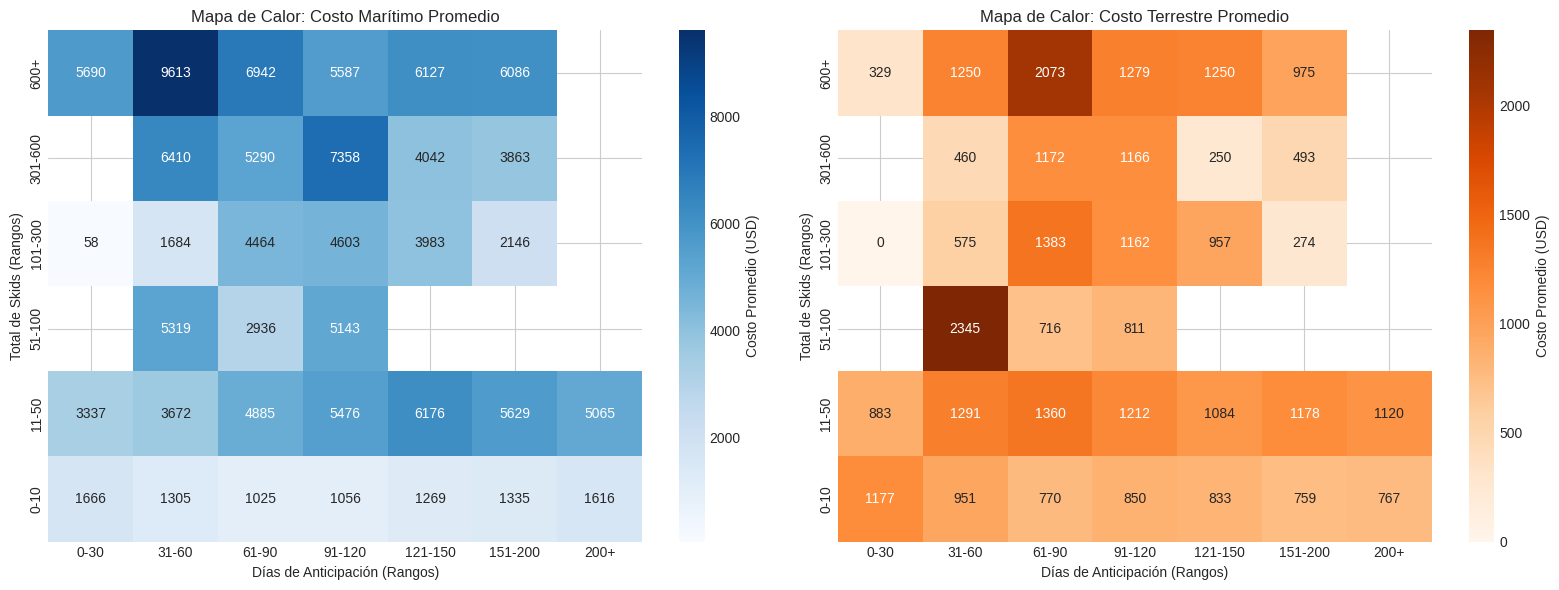

In [27]:
# 1. Crear rangos (bins) lógicos para los Días de Anticipación
lead_bins = [0, 30, 60, 90, 120, 150, 200, np.inf]
lead_labels = ['0-30', '31-60', '61-90', '91-120', '121-150', '151-200', '200+']
df['lead_time_rango'] = pd.cut(df['lead_time_days'], bins=lead_bins, labels=lead_labels)

# 2. Crear rangos (bins) lógicos para el Total de Skids
skid_bins = [0, 10, 50, 100, 300, 600, np.inf]
skid_labels = ['0-10', '11-50', '51-100', '101-300', '301-600', '600+']
df['skids_rango'] = pd.cut(df['total_skids'], bins=skid_bins, labels=skid_labels)

# 3. Crear tablas dinámicas con observed=False para evitar el FutureWarning
ocean_pivot = df.pivot_table(index='skids_rango', columns='lead_time_rango', values='ocean_cost', aggfunc='mean', observed=False)
land_pivot = df.pivot_table(index='skids_rango', columns='lead_time_rango', values='land_cost', aggfunc='mean', observed=False)

# 4. Graficar los mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(ocean_pivot.iloc[::-1], annot=True, fmt=".0f", cmap="Blues", ax=axes[0],
            cbar_kws={'label': 'Costo Promedio (USD)'})
axes[0].set_title('Mapa de Calor: Costo Marítimo Promedio')
axes[0].set_xlabel('Días de Anticipación (Rangos)')
axes[0].set_ylabel('Total de Skids (Rangos)')

sns.heatmap(land_pivot.iloc[::-1], annot=True, fmt=".0f", cmap="Oranges", ax=axes[1],
            cbar_kws={'label': 'Costo Promedio (USD)'})
axes[1].set_title('Mapa de Calor: Costo Terrestre Promedio')
axes[1].set_xlabel('Días de Anticipación (Rangos)')
axes[1].set_ylabel('Total de Skids (Rangos)')

plt.tight_layout()
plt.show()

### Análisis de Relación Multivariable: Volumen, Anticipación y Costos

Los mapas de calor revelan cómo interactúan simultáneamente el volumen de carga (skids) y los días de anticipación (lead time) con los costos promedio de ambos trayectos, demostrando dinámicas de precios muy distintas.

**1. Comportamiento del Costo Marítimo**
* Existe una relación general predecible: las filas superiores (mayor cantidad de skids) concentran los colores más oscuros, indicando que el costo marítimo escala con el volumen.
* El pico máximo de costo marítimo promedio alcanza los 9,613 USD y ocurre en envíos masivos (más de 600 skids) planificados con 31 a 60 días de anticipación
* Una anomalía operativa interesante es que, para estos mismos volúmenes masivos (600+ skids), coordinar con muy poca anticipación (0 a 30 días) resulta significativamente más económico (5,690 USD) que hacerlo con uno o dos meses de antelación. Esto sugiere la posible existencia de tarifas de oportunidad o liquidación de espacios a bordo a último minuto.

**2. Comportamiento del Costo Terrestre**
* A diferencia del flete marítimo, el costo terrestre no escala de forma lineal ni proporcional al volumen de la carga.
* El mayor pico de costo terrestre no se presenta en los envíos de mayor tamaño, sino en un rango medio (51 a 100 skids) coordinado con 61 a 90 días de anticipación, alcanzando un promedio atípico de 2,345 USD.
* Los envíos en el rango de 11 a 50 skids mantienen una banda de precios sumamente estable (entre 883 USD y 1,360 USD) independientemente de los días de anticipación con los que se planifique el viaje.

**Conclusión**
La variable de anticipación no garantiza automáticamente mejores tarifas logísticas. El modelo actual indica que las tarifas terrestres responden a ineficiencias puntuales o rutas específicas (como se evidencia en el pico de volúmenes medios), más que a la cantidad de skids. Por su parte, la estrategia de reserva marítima para grandes volúmenes debe revisarse, ya que las tarifas de mediano plazo (31-60 días) están penalizando el costo frente a los envíos inmediatos (0-30 días).

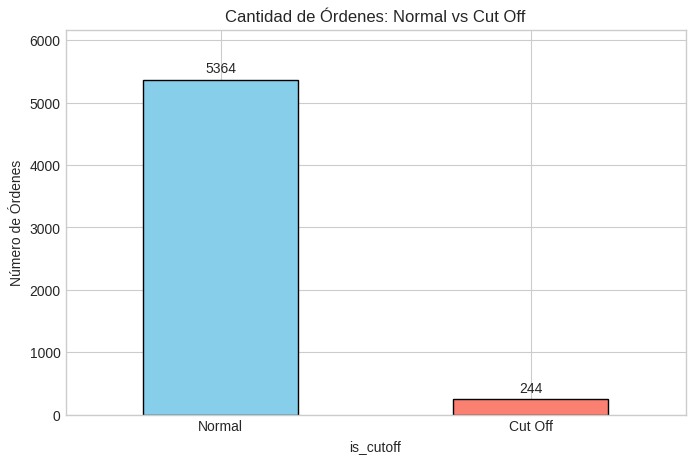

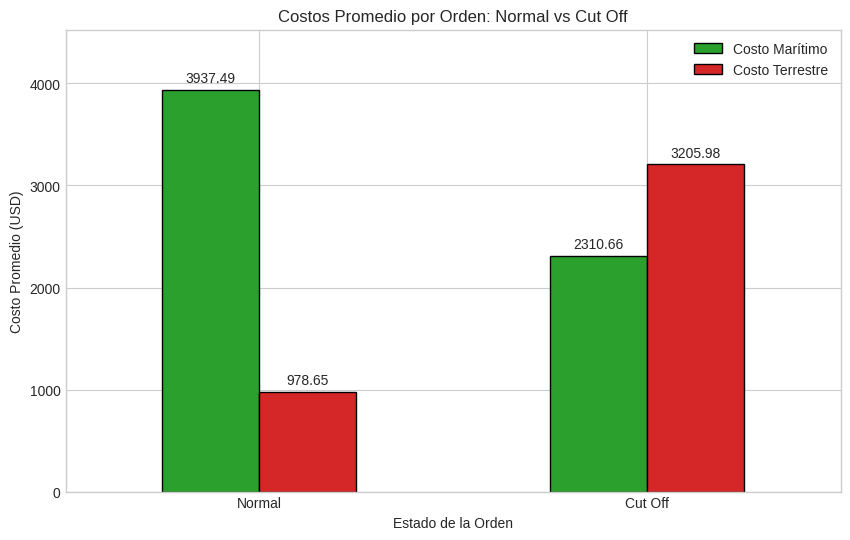

Rutas desviadas más comunes:
route_change
Shanghai -> Toronto, ON (Desviado a: Vancouver, BC)       19
Shanghai -> Savannah, GA (Desviado a: Los Angeles, CA)    16
Shanghai -> Chicago, IL (Desviado a: Los Angeles, CA)     13
Shanghai -> Savannah, GA (Desviado a: New York, NY)        7
Shanghai -> Miami, FL (Desviado a: Los Angeles, CA)        2
Shanghai -> Omaha, NE (Desviado a: Los Angeles, CA)        2
Shanghai -> Vancouver, BC (Desviado a: Vancouver, BC)      2
Shanghai -> Chicago, IL (Desviado a: Oakland, CA)          1
Shanghai -> Columbus, OH (Desviado a: Los Angeles, CA)     1
Shanghai -> Denver, CO (Desviado a: Seattle, WA)           1
Name: count, dtype: int64


In [16]:
# Asegurar que la columna is_cutoff exista (si no corriste la celda anterior)
if 'is_cutoff' not in df.columns:
    df['is_cutoff'] = df['ocean_value_change'] == 'CutOff'

# 1. Gráfica estándar de Volumen con etiquetas de datos
plt.figure(figsize=(8, 5))
conteo = df['is_cutoff'].value_counts().rename(index={False: 'Normal', True: 'Cut Off'})
ax1 = conteo.plot(kind='bar', color=['skyblue', 'salmon'], edgecolor='black')

# Agregar los valores numéricos enteros (%d) sobre las barras
for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', padding=3)

plt.title('Cantidad de Órdenes: Normal vs Cut Off')
plt.ylabel('Número de Órdenes')
plt.xticks(rotation=0)
plt.margins(y=0.15) # Espacio extra arriba para que el texto no se corte
plt.show()

# 2. Gráfica estándar de Costos Promedio con etiquetas de datos
costos_promedio = df.groupby('is_cutoff')[['ocean_cost', 'land_cost']].mean()
costos_promedio.index = ['Normal', 'Cut Off']

ax2 = costos_promedio.plot(kind='bar', figsize=(10, 6), color=['#2ca02c', '#d62728'], edgecolor='black')

# Agregar los valores numéricos con dos decimales (%.2f) sobre las barras
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', padding=3)

plt.title('Costos Promedio por Orden: Normal vs Cut Off')
plt.ylabel('Costo Promedio (USD)')
plt.xlabel('Estado de la Orden')
plt.legend(['Costo Marítimo', 'Costo Terrestre'])
plt.xticks(rotation=0)
plt.margins(y=0.15)
plt.show()



### Análisis de Excepciones Operativas (Cut Offs) y su Impacto Financiero

**1. Volumen de Excepciones Operativas**
* Las órdenes con estado Cut Off representan una excepción operativa poco frecuente en la cadena de suministro, totalizando solo 244 incidentes frente a un bloque consolidado de 5,364 órdenes normales.

**2. Inversión de la Estructura de Costos**
* En un flujo logístico normal, el gasto principal recae en el flete marítimo con un promedio de 3,937 USD, manteniendo el costo terrestre controlado en 978 USD.
* Cuando se ejecuta un Cut Off, esta estructura financiera se invierte radicalmente: el costo marítimo promedio se reduce fuertemente a 2,310 USD, pero el gasto de transporte terrestre se dispara, triplicándose hasta alcanzar los 3,205 USD.

**3. Patrón Geográfico de los Desvíos**
* Todos los desvíos más recurrentes tienen su origen en Shanghai y comparten un comportamiento geográfico sistemático.
* La mercancía programada originalmente para destinos en el este o centro de Norteamérica (Toronto, Savannah, Chicago, Miami) sufre recortes de ruta y es descargada prematuramente en puertos de la costa oeste del Pacífico, principalmente en Vancouver y Los Angeles.

**Conclusión**
La reducción en la factura marítima durante un Cut Off es un espejismo financiero, ya que el recorte de la ruta oceánica obliga a la mercancía a cruzar todo el continente norteamericano por tierra. El patrón de descargar carga en la costa oeste (Los Angeles o Vancouver) que originalmente iba destinada al atlántico o al medio oeste (Savannah o Toronto) explica directamente el aumento drástico en los costos terrestres. Estos desvíos logran mitigar cuellos de botella portuarios o retrasos marítimos, pero resuelven el problema en el agua a expensas de un trayecto terrestre transcontinental que encarece severamente la operación.